# Figure 3 — Viral pseudogenome expression maps

Standalone script for manuscript code availability. Produces circular pseudogenome
expression plots for three reference viruses:

- **AIL3.217** (Pimascovirales_01)
- **AIL3.53** (Mimiviridae)
- **AIL3.4** (Mesomimiviridae)

Radial bar height = mean UMIs per expressing cell; color = number of expressing cells (viridis).

No external project modules are required beyond standard Python packages.

In [1]:
import os
import re
from pathlib import Path
from typing import Dict, Optional, Sequence, Tuple, Union

import anndata as ad
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from Bio import SeqIO
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from scipy.io import mmread


def load_star_matrix(path: Union[str, Path], sample_name: Optional[str] = None) -> sc.AnnData:
    """Load a STARsolo raw matrix directory into AnnData (cells x genes)."""
    path = Path(path)
    if not path.is_dir():
        raise FileNotFoundError(f"STAR matrix path does not exist: {path}")

    X = mmread(path / "matrix.mtx").tocsr().T
    features = pd.read_csv(path / "features.tsv", sep="\t", header=None)
    barcodes = pd.read_csv(path / "barcodes.tsv", sep="\t", header=None)

    adata = sc.AnnData(X, dtype=X.dtype)
    adata.var_names = features[0].astype(str)
    adata.obs_names = barcodes[0].astype(str)
    adata.var_names_make_unique()
    adata.obs_names_make_unique()
    if sample_name is not None:
        adata.obs["sample"] = sample_name
    adata.layers["counts"] = adata.X.copy()
    return adata


def load_star_samples(paths: Dict[str, Union[str, Path]]) -> sc.AnnData:
    """Load and concatenate multiple STARsolo matrices."""
    adata_dict = {
        sample: load_star_matrix(path, sample_name=sample)
        for sample, path in paths.items()
    }
    adata = ad.concat(
        adata_dict,
        label="sample",
        join="outer",
        merge="same",
        index_unique=None,
    )
    adata.obs_names = [
        f"{bc.replace('-1', '')}.{samp}"
        for bc, samp in zip(adata.obs_names, adata.obs["sample"])
    ]
    return adata


def parse_gff(gff_file: Union[str, Path]) -> pd.DataFrame:
    records = []
    with Path(gff_file).open() as handle:
        for line in handle:
            if line.startswith("#"):
                continue
            fields = line.strip().split("\t")
            if len(fields) != 9:
                continue
            contig, _, feature, start, end, _, strand, _, attrs = fields
            if feature not in {"gene", "CDS", "exon"}:
                continue
            start_i, end_i = int(start), int(end)
            gene_match = re.search(r'gene_id "?([^";]+)', attrs)
            gene_id = gene_match.group(1) if gene_match else f"{contig}_{start_i}_{end_i}"
            records.append(
                {
                    "contig": contig,
                    "start": start_i,
                    "end": end_i,
                    "strand": strand,
                    "gene_id": gene_id,
                }
            )
    return pd.DataFrame(records)


def compute_gene_mean_umis_per_expressing_cell(adata) -> pd.Series:
    X = adata.X
    total_umis = np.asarray(X.sum(axis=0)).ravel()
    n_cells = np.asarray((X > 0).sum(axis=0)).ravel()
    mean_umis = np.divide(
        total_umis,
        n_cells,
        out=np.zeros_like(total_umis, dtype=float),
        where=n_cells > 0,
    )
    return pd.Series(mean_umis, index=adata.var_names)


def compute_gene_ncells(adata) -> pd.Series:
    ncells = np.asarray((adata.X > 0).sum(axis=0)).ravel()
    return pd.Series(ncells, index=adata.var_names)


def build_pseudogenome_from_fasta(
    gff: pd.DataFrame,
    fasta_file: Union[str, Path],
    spacer: int = 10000,
) -> Tuple[pd.DataFrame, Dict[str, int], Dict[str, int], int]:
    contig_lengths = {
        record.id: len(record.seq)
        for record in SeqIO.parse(fasta_file, "fasta")
    }
    present = set(gff["contig"])
    contig_lengths = dict(
        sorted(
            ((k, v) for k, v in contig_lengths.items() if k in present),
            key=lambda item: item[1],
            reverse=True,
        )
    )
    offsets: Dict[str, int] = {}
    current_offset = 0
    for contig, length in contig_lengths.items():
        offsets[contig] = current_offset
        current_offset += length + spacer

    gff = gff.copy()
    gff["pseudo_start"] = gff.apply(lambda row: row["start"] + offsets[row["contig"]], axis=1)
    gff["pseudo_end"] = gff.apply(lambda row: row["end"] + offsets[row["contig"]], axis=1)
    return gff, offsets, contig_lengths, current_offset


def _auto_umi_scale(observed_max: float) -> Tuple[int, list]:
    if observed_max <= 10:
        return 10, [2, 5, 10]
    if observed_max <= 20:
        return 20, [5, 10, 20]
    if observed_max <= 50:
        return 50, [5, 10, 25, 50]
    if observed_max <= 100:
        return 100, [10, 25, 50, 100]
    max_umi = int(np.ceil(observed_max / 50.0) * 50)
    return max_umi, [int(max_umi * 0.25), int(max_umi * 0.50), int(max_umi)]


def plot_pseudogenome_circos(
    adata,
    gff_file: Union[str, Path],
    fasta_file: Union[str, Path],
    virus_name: str,
    output: Union[str, Path],
    *,
    spacer: int = 1000,
    figsize: Tuple[float, float] = (6, 6),
    highlight_genes: Optional[Dict[str, str]] = None,
    max_umi_for_scaling: Optional[int] = None,
    reference_umis: Optional[Sequence[int]] = None,
    auto_scale: bool = True,
    show: bool = True,
):
    gff = parse_gff(gff_file)
    n_orfs = gff["gene_id"].nunique()

    umi_counts = compute_gene_mean_umis_per_expressing_cell(adata)
    gene_ncells = compute_gene_ncells(adata)
    gff = gff.copy()
    gff["umis"] = gff["gene_id"].map(umi_counts).fillna(0)
    gff["ncells"] = gff["gene_id"].map(gene_ncells).fillna(0)

    gff, _, _, genome_length = build_pseudogenome_from_fasta(gff, fasta_file, spacer=spacer)

    observed_max = float(gff["umis"].max())
    if auto_scale or max_umi_for_scaling is None:
        max_umi_for_scaling, reference_umis = _auto_umi_scale(observed_max)
    elif reference_umis is None:
        reference_umis = [
            int(max_umi_for_scaling * 0.25),
            int(max_umi_for_scaling * 0.50),
            int(max_umi_for_scaling),
        ]

    def scale_umi(x):
        return np.sqrt(x) / np.sqrt(max_umi_for_scaling)

    cmap = plt.colormaps["viridis"]
    max_ncells = max(float(gff["ncells"].max()), 1.0)
    sm = ScalarMappable(cmap=cmap, norm=Normalize(vmin=0, vmax=max_ncells))
    sm.set_array([])

    inner_radius = 4.7
    bar_base = 0.2
    bar_scale = 1.6

    fig, ax = plt.subplots(figsize=figsize, subplot_kw={"projection": "polar"}, dpi=300)
    ax.set_theta_direction(-1)
    ax.set_theta_offset(np.pi / 2)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines["polar"].set_visible(False)

    theta = np.linspace(0, 2 * np.pi, 2000)
    ax.plot(theta, np.ones_like(theta) * inner_radius, lw=2, color="black", zorder=3)

    base_angle = np.deg2rad(35)
    for i, umi in enumerate(reference_umis):
        if umi > max_umi_for_scaling:
            continue
        ring_radius = inner_radius + bar_base + bar_scale * min(scale_umi(umi), 1.2)
        ax.plot(theta, np.ones_like(theta) * ring_radius, ls="--", lw=0.4, color="dimgrey", alpha=1, zorder=0)
        ax.text(
            base_angle - np.deg2rad(i * 2),
            ring_radius,
            f"{umi:,} UMIs/cell",
            fontsize=10,
            color="black",
            ha="left",
            va="center",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=0),
            zorder=10,
        )

    for _, row in gff.iterrows():
        if row["umis"] <= 0:
            continue
        start_angle = 2 * np.pi * row["pseudo_start"] / genome_length
        end_angle = 2 * np.pi * row["pseudo_end"] / genome_length
        width = end_angle - start_angle
        height = bar_base + bar_scale * min(scale_umi(row["umis"]), 1.0)
        ax.bar(
            x=start_angle,
            height=height,
            width=width,
            bottom=inner_radius,
            align="edge",
            color=cmap(row["ncells"] / max_ncells),
            edgecolor="black",
            linewidth=0.3,
            alpha=0.9,
            zorder=2,
        )

    if highlight_genes:
        for gene_id, label in highlight_genes.items():
            gene_rows = gff[gff["gene_id"] == gene_id]
            if gene_rows.empty:
                print(f"Warning: highlighted gene not found: {gene_id}")
                continue
            row = gene_rows.iloc[0]
            midpoint = (row["pseudo_start"] + row["pseudo_end"]) / 2
            angle = 2 * np.pi * midpoint / genome_length
            angle_deg = np.degrees(angle)
            gene_height = bar_base + bar_scale * min(scale_umi(row["umis"]), 1.0)
            line_start = inner_radius + gene_height + 0.06
            line_end = line_start + 0.26
            label_radius = line_end + 0.8
            display_angle = (90 - angle_deg) % 360
            rotation = display_angle + 180 if 90 < display_angle < 270 else display_angle
            ax.plot([angle, angle], [line_start, line_end], color="black", lw=2.2, zorder=5)
            ax.text(
                angle,
                label_radius,
                label,
                rotation=rotation,
                rotation_mode="default",
                ha="center",
                va="center",
                fontsize=12,
                fontweight="bold",
                zorder=6,
            )

    cax = fig.add_axes([0.98, 0.72, 0.015, 0.18])
    cbar = plt.colorbar(sm, cax=cax)
    cbar.set_label("Number of expressing cells", fontsize=10)
    cbar.ax.tick_params(labelsize=10)

    if genome_length >= 1e6:
        genome_label = f"{genome_length / 1e6:.2f} Mbp"
    elif genome_length >= 1e3:
        genome_label = f"{genome_length / 1e3:.1f} kbp"
    else:
        genome_label = f"{genome_length} bp"

    ax.text(
        0,
        0,
        f"{virus_name}\n\n{genome_label}\n{n_orfs:,} ORFs",
        ha="center",
        va="center",
        fontsize=16,
        fontweight="bold",
    )

    ax.set_ylim(0, inner_radius + bar_base + bar_scale + 0.4)
    plt.subplots_adjust(left=0.02, right=0.98, top=0.98, bottom=0.02)

    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output, dpi=300, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)
    print(f"Saved plot to: {output}")
    return fig, ax

In [2]:
# --- configuration ---
ROOT = Path("/home/labs/vardi/amirz/pairing/Alps_All_MetaG")
STAR_ROOT = ROOT / "gene_expression/STAR"
GENOME_DIR = ROOT / "genomes_of_interest/genomes"
ANNOTATION_DIR = ROOT / "genomes_of_interest/proteins"
OUTPUT_DIR = ROOT / "gene_expression/figure_3_viral_genomes"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

STAR_SAMPLES = ["Alps2", "Alps5", "Alps_Amir"]
FIGSIZE = (6, 6)

VIRUSES = {
    "AIL3.217": {
        "taxa": "Opalozoa",
        "virus_name": "AIL3.217 (Pimascovirales_01)",
        "highlight_genes": {
            "k127_7298095_31": "H3-H4",
            "k127_8407731_18": "RHO",
            "k127_4821179_18": "PolB",
        },
    },
    "AIL3.53": {
        "taxa": "Dinophyceae",
        "virus_name": "AIL3.53 (Mimiviridae)",
        "highlight_genes": {
            "k127_8640956_9": "PolB",
            "k127_2523651_2": "MCP",
            "k127_835695_3": "MCP",
            "k127_1234125_3": "HSP90",
            "k127_8842909_4": "HSP70",
            "k127_5327160_105": "RHO",
        },
    },
    "AIL3.4": {
        "taxa": "Chrysophyceae",
        "virus_name": "AIL3.4 (Mesomimiviridae)",
        "highlight_genes": {
            "k127_3188997_83": "MCP",
            "k127_432628_63": "MCP",
            "k127_432628_97": "PolB",
            "k127_3188997_78": "RHO",
            "k127_10212343_16": "TIR",
        },
    },
}


def star_paths_for_taxon(taxa: str) -> Dict[str, Path]:
    return {
        sample: STAR_ROOT / taxa / f"{sample}_Solo.out/Gene/raw"
        for sample in STAR_SAMPLES
    }

### Generate pseudogenome expression maps for all three viruses


=== AIL3.217 (Opalozoa) ===
Loaded 37 cells x 342 genes


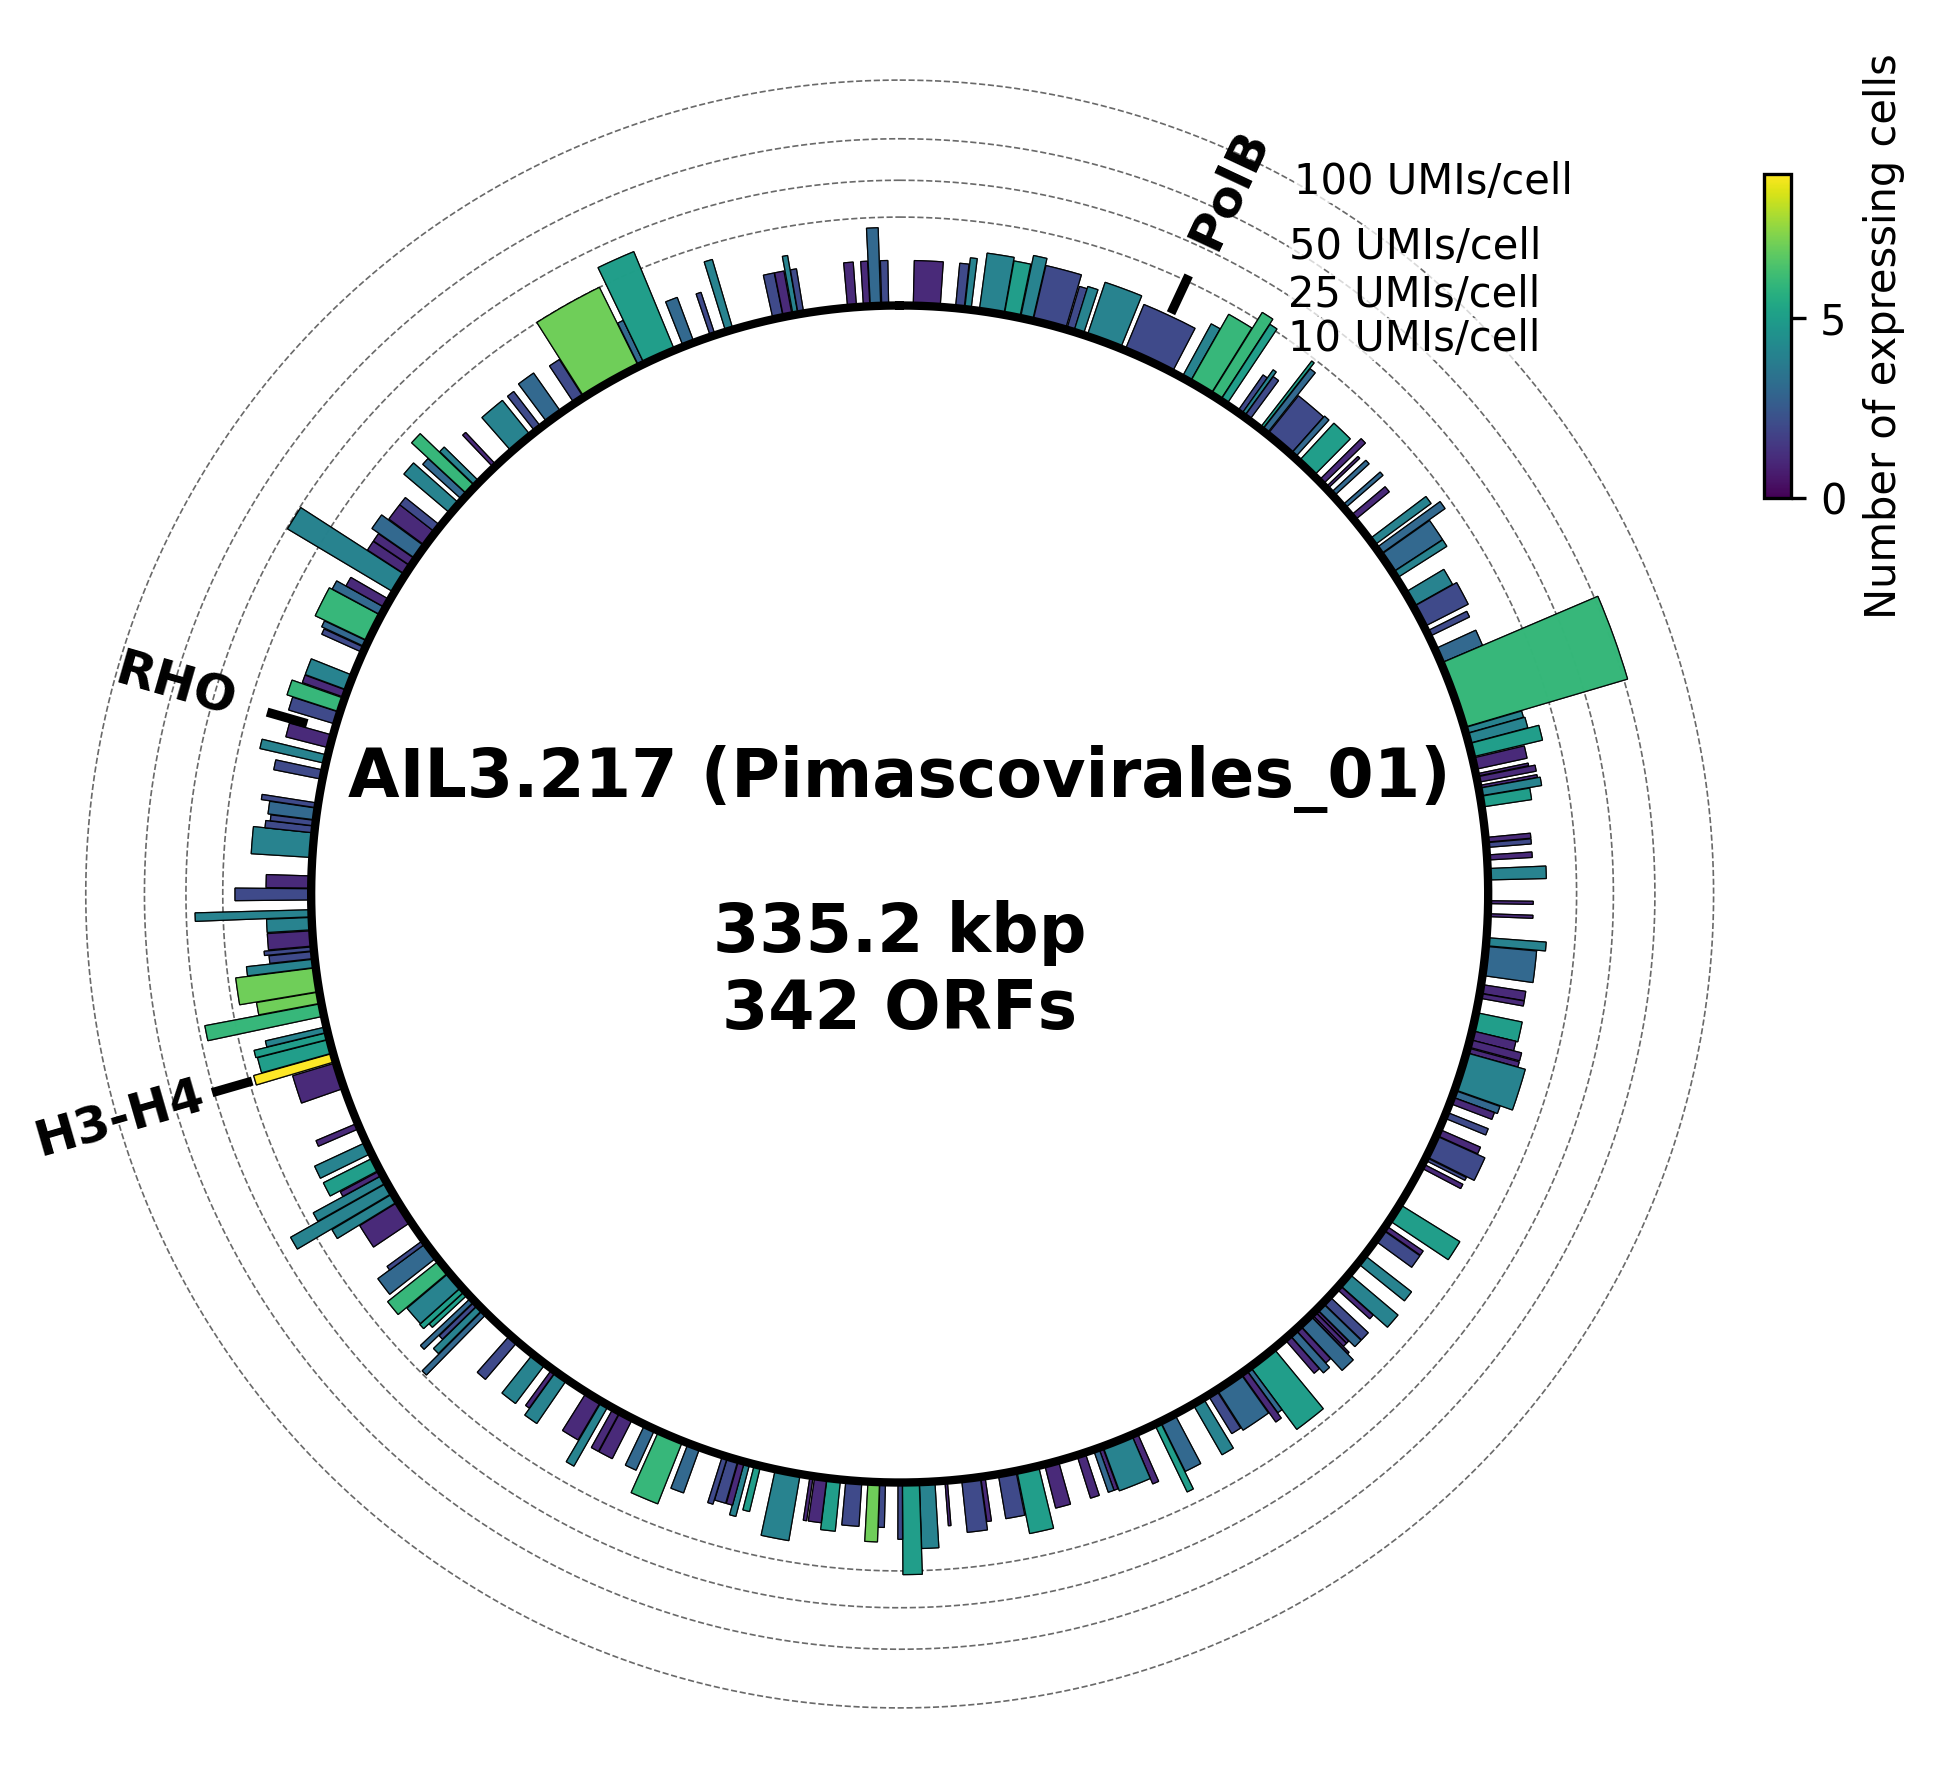

Saved plot to: /home/labs/vardi/amirz/pairing/Alps_All_MetaG/gene_expression/figure_3_viral_genomes/AIL3.217.viral_pseudogenome_mean.png

=== AIL3.53 (Dinophyceae) ===
Loaded 422 cells x 341 genes


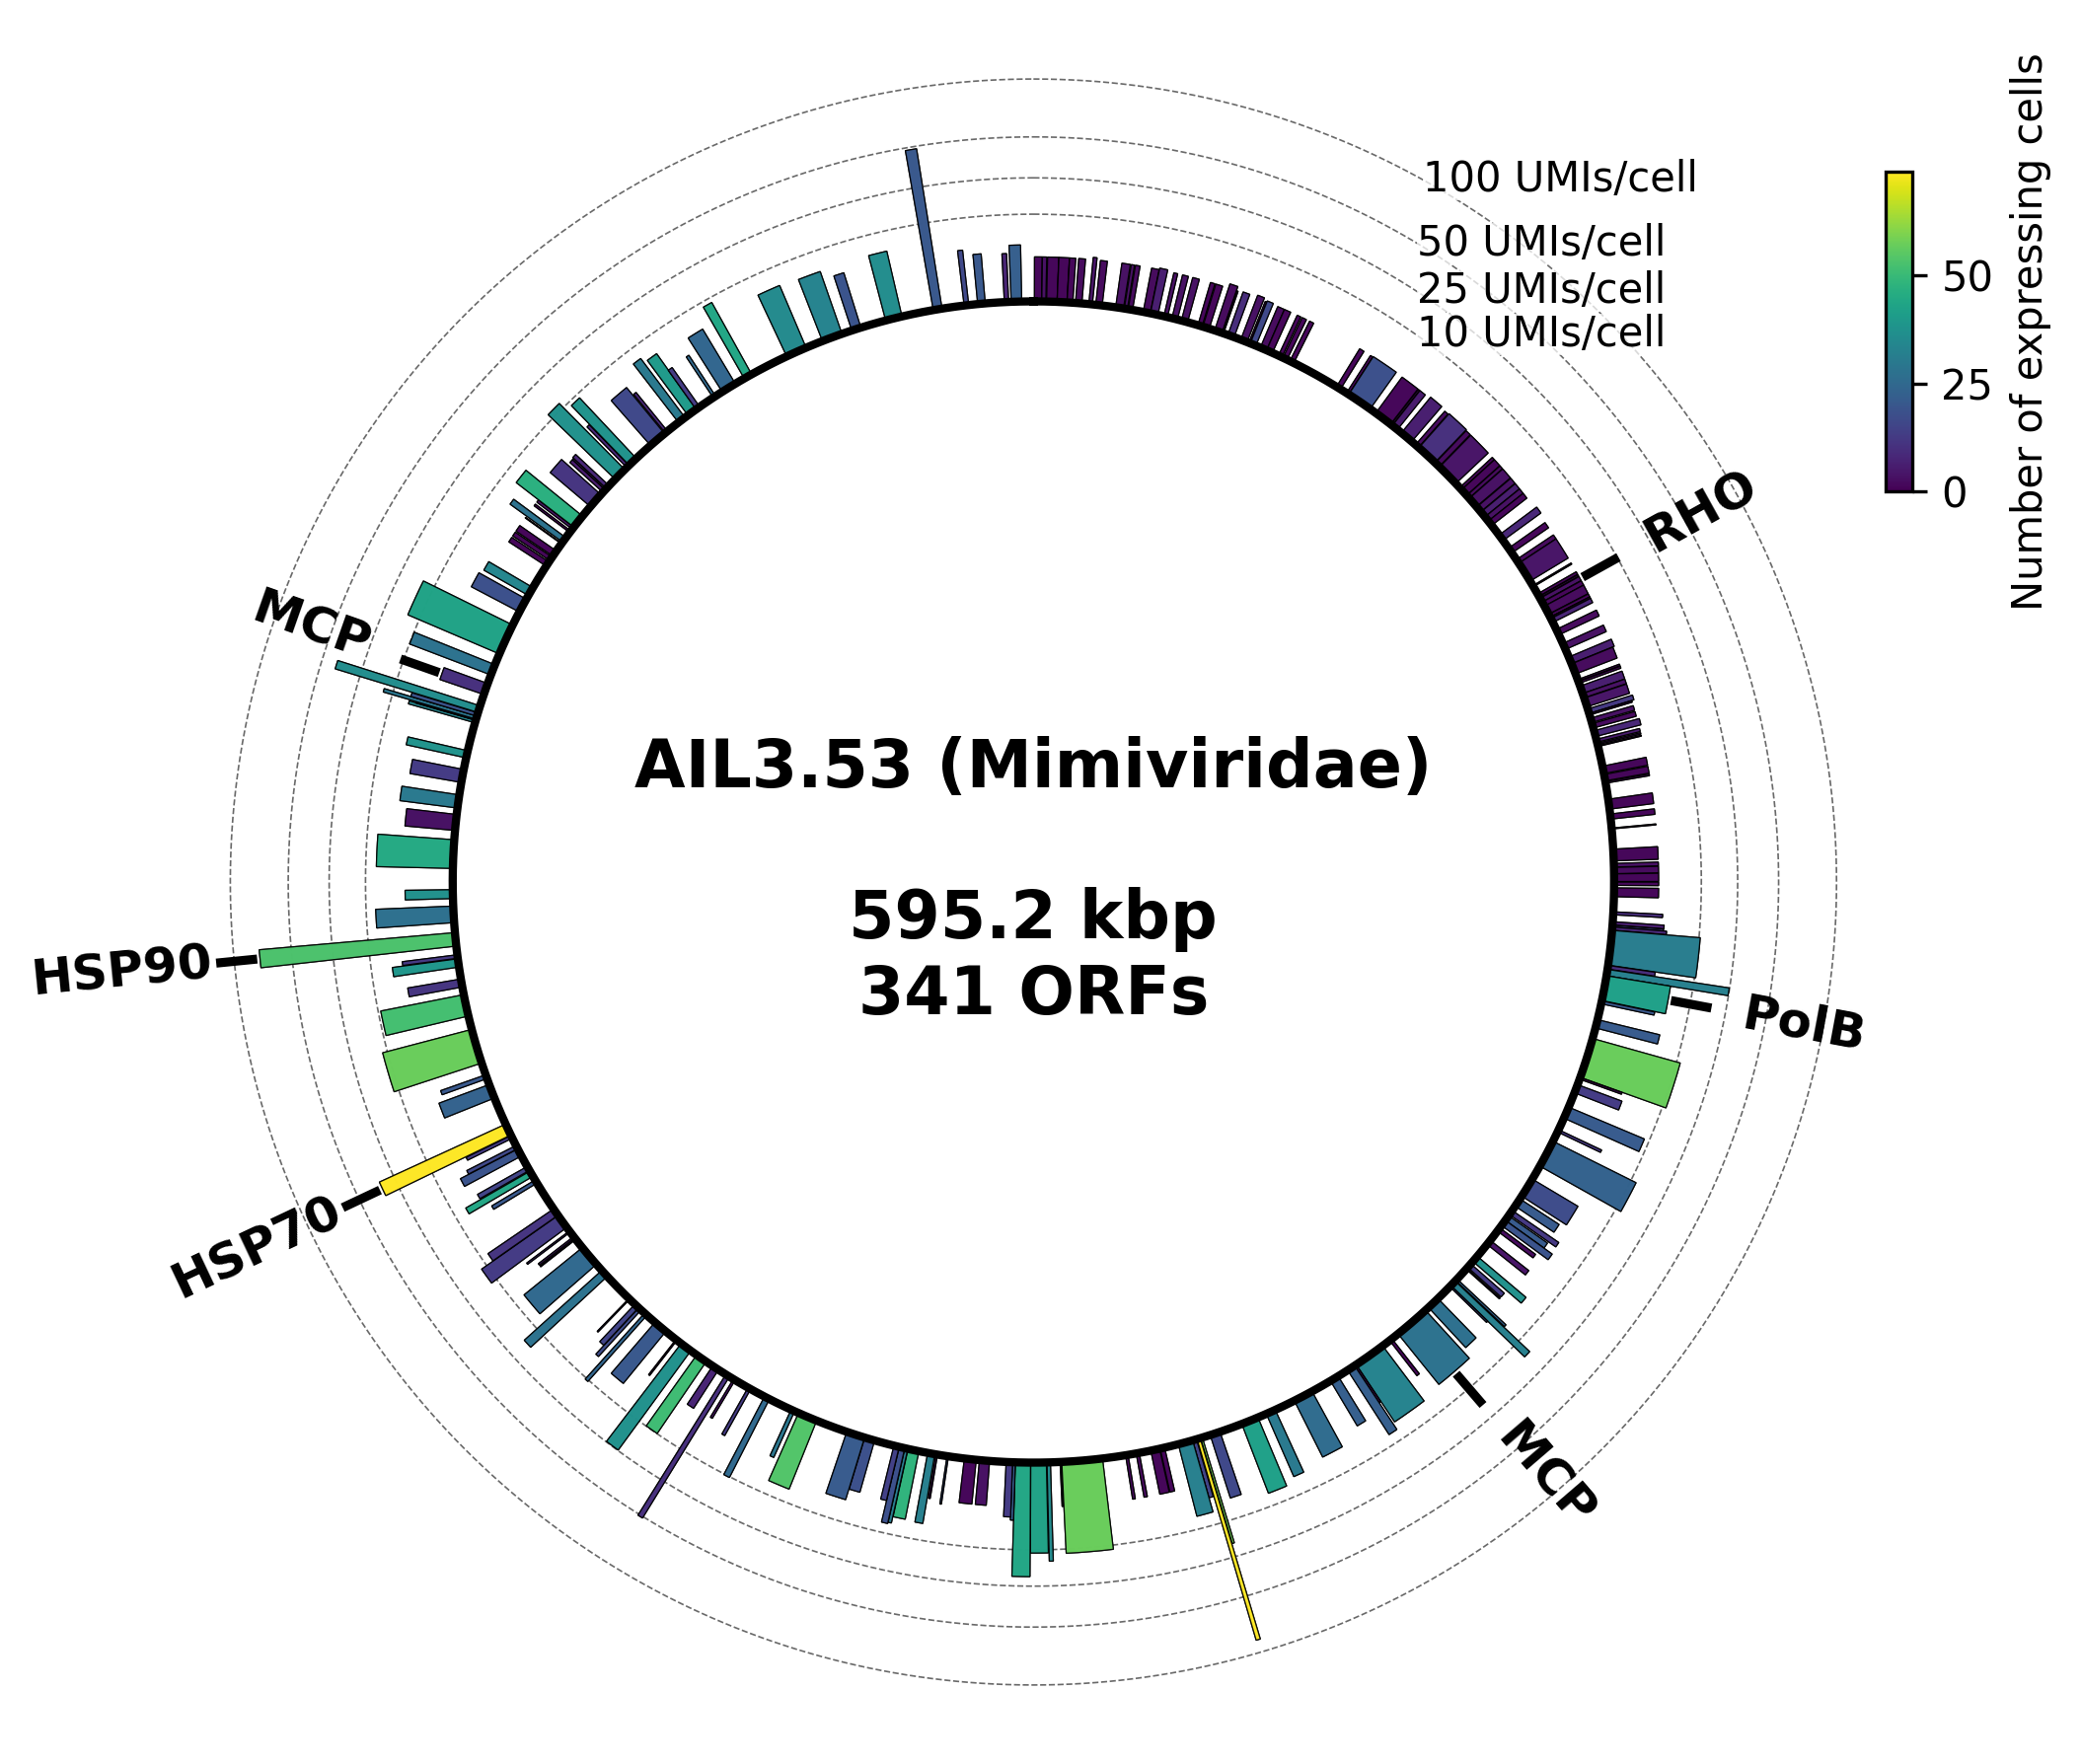

Saved plot to: /home/labs/vardi/amirz/pairing/Alps_All_MetaG/gene_expression/figure_3_viral_genomes/AIL3.53.viral_pseudogenome_mean.png

=== AIL3.4 (Chrysophyceae) ===
Loaded 1,407 cells x 503 genes


/home/labs/vardi/amirz/.conda/envs/py38/lib/python3.8/site-packages/anndata/_core/anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


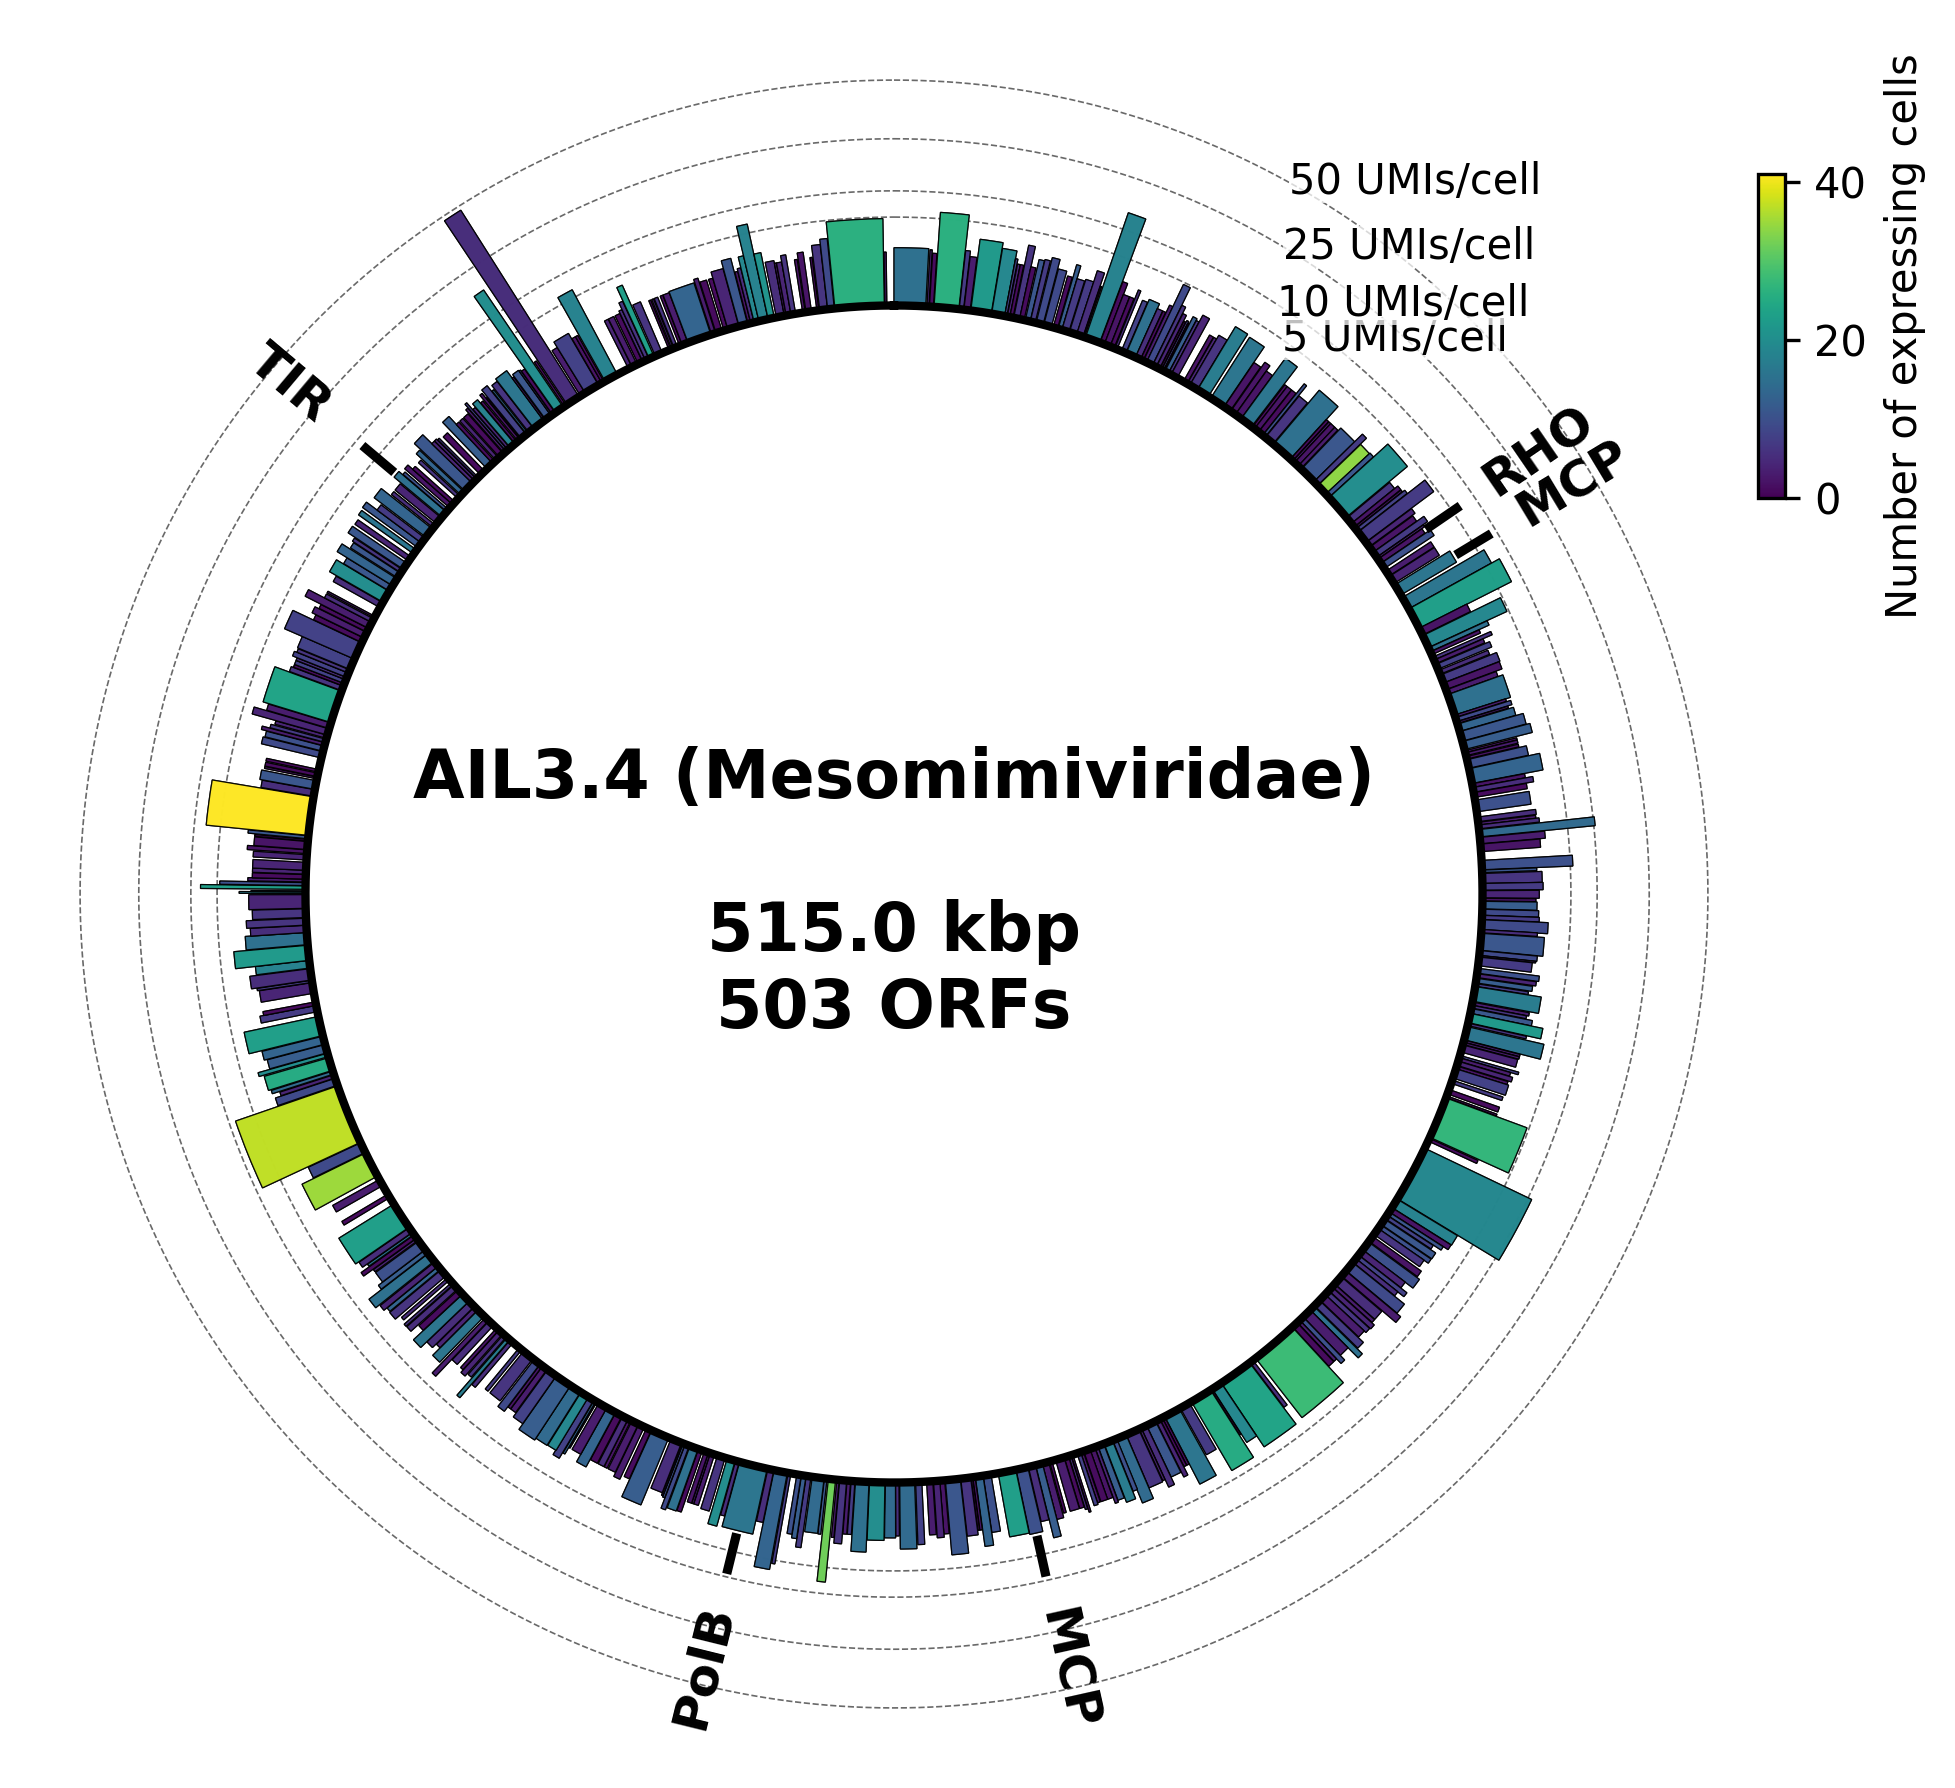

Saved plot to: /home/labs/vardi/amirz/pairing/Alps_All_MetaG/gene_expression/figure_3_viral_genomes/AIL3.4.viral_pseudogenome_mean.png


In [3]:
for virus_id, cfg in VIRUSES.items():
    print(f"\n=== {virus_id} ({cfg['taxa']}) ===")
    adata = load_star_samples(star_paths_for_taxon(cfg["taxa"]))
    print(f"Loaded {adata.n_obs:,} cells x {adata.n_vars:,} genes")

    plot_pseudogenome_circos(
        adata=adata,
        gff_file=ANNOTATION_DIR / f"{virus_id}.fltr.gtf",
        fasta_file=GENOME_DIR / f"{virus_id}.fltr.fa",
        virus_name=cfg["virus_name"],
        highlight_genes=cfg["highlight_genes"],
        figsize=FIGSIZE,
        output=OUTPUT_DIR / f"{virus_id}.viral_pseudogenome_mean.png",
    )